# Información contextual de cierres programados LCS y su correspondencia con PEMS-BAY

**Tecnológico de Monterrey - Maestría en Inteligencia Artificial Aplicada**  
**Proyecto Integrador - Equipo 42 (Route Intelligence)**

**Integrantes:**

- Luis Ángel Herrera Flores
- Francisco Natanael Ortiz Martínez
- Edgar Iván Rosas Gómez

**Análisis complementario para el Avance 5 - Distrito 4 de Caltrans, enero-junio de 2017**  


**Contexto.** El proyecto busca estimar tiempos de viaje para apoyar la planeación y la eventual replaneación de rutas. En el Avance 4 se reconstruyeron tiempos de desplazamiento utilizando patrones históricos y un número limitado de consultas origen-destino simuladas. Como línea complementaria, el asesor propuso investigar información sobre acontecimientos potencialmente conocidos antes de ocurrir, como obras o cierres programados, que posteriormente podría representarse mediante variables estructuradas o *embeddings* para pronosticar las condiciones del tráfico.

**Pregunta de esta exploración.** ¿Qué solicitudes del *Lane Closure System* (LCS) de Caltrans pueden vincularse con las 273 aristas de corredor del grafo del proyecto y qué información espacial, temporal y operativa proporcionan? Se distinguen carreteras principales, rampas y otras instalaciones; intervenciones localizadas por tramos o por una única postmilla; y horarios programados frente a información operativa reportada posteriormente.

**Contribución y límites.** Esta notebook reconstruye un conjunto de eventos LCS vinculados espacialmente con el grafo y cuantifica su presencia programada sobre una malla teórica de cinco minutos. **No prueba cierres ejecutados, impactos en velocidades, disponibilidad pública anticipada ni mejora predictiva.** Su finalidad es definir una fuente contextual auditable para un experimento posterior con las series de tráfico. Enero-mayo se utiliza para caracterización y junio como diagnóstico adicional: junio ya fue utilizado en el Avance 4 y no es una prueba completamente inédita.

**Resumen de resultados.** Se analizaron **27,448 solicitudes LCS** de enero-junio de 2017; **1,806** presentan alguna asociación espacial con **242 de las 273 aristas de corredor** del proyecto. El **40.5 % de las solicitudes con geometría válida** está representado mediante una sola postmilla, por lo que esas ubicaciones puntuales no pueden tratarse como intervalos de longitud positiva. En enero-mayo, la presencia programada de solicitudes `Freeway` aprobadas cubre el **0.865 %** de los pares arista-instante de cinco minutos, con mayor concentración nocturna (**1.615 %**) que diurna (**0.330 %**). Aunque los registros administrativos suelen crearse con anticipación, la versión histórica no permite establecer qué información exacta estaba disponible antes de cada evento ni demuestra cambios en las velocidades. La evaluación de esos posibles efectos queda para un experimento posterior.

**Fuentes.** Exportaciones LCS de enero-marzo y abril-junio de 2017, metadatos originales de estaciones del Distrito 4 y `edges.csv` del conjunto `routing_dataset_v1` construido en el proyecto. Los resultados pueden reproducirse con esos archivos sin modificar las fuentes.

## 0. Archivos, alcance y vocabulario

La ejecución requiere los dos TXT de solicitudes LCS, `d04_text_meta_2017_01_04.txt` con los metadatos de sensores y `edges.csv` del grafo construido previamente. En Google Colab pueden ubicarse en `/content/` o en la carpeta `Route Intelligence` de Drive. Los archivos de salida se guardan por separado.

**LCS** (*Lane Closure System*) es el sistema administrativo de Caltrans para solicitar y actualizar cierres temporales. **PEMS-BAY** es el conjunto histórico de mediciones de velocidad utilizado como referencia para la red del proyecto. **`DB ID`** identifica una solicitud administrativa, no una intervención ejecutada. **`Abs_PM`** (*absolute postmile*) identifica posiciones longitudinales en millas sobre una carretera.

El grafo preparado en el proyecto contiene **345 aristas**, de las cuales **273 son de corredor** entre dos sensores y **72 son auxiliares**, entre sensores y nodos de intercambio. Solo las primeras poseen los dos extremos georreferenciados por postmillas necesarios para esta asociación. Las conexiones auxiliares permanecen en el grafo para cálculos de rutas, pero no se emparejan por postmillas.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
DRIVE_ROOT = Path('/content/drive/MyDrive/Route Intelligence')
try:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    pass  # Jupyter local

EDGES_PATH = DRIVE_ROOT / 'routing_dataset_v1' / 'edges.csv'
if not EDGES_PATH.is_file() and (ROOT / 'edges.csv').is_file():
    EDGES_PATH = ROOT / 'edges.csv'

# Por defecto, persistir en la carpeta del proyecto en Drive si está montado.
SALIDA = (DRIVE_ROOT if DRIVE_ROOT.is_dir() else ROOT) / 'lcs_d04_2017_exploracion'
SALIDA.mkdir(parents=True, exist_ok=True)

def localizar(nombre, alternativas=()):
    for raiz in (ROOT, Path.cwd(), DRIVE_ROOT, DRIVE_ROOT / 'routing_dataset_v1'):
        for opcion in (nombre, *alternativas):
            p = raiz / opcion
            if p.is_file():
                return p
    raise FileNotFoundError(f'Falta {nombre}; compruebe /content/ y {DRIVE_ROOT}.')

LCS_T1 = localizar('LCS_D04_2017_enero_marzo.txt')
LCS_T2 = localizar('LCS_D04_2017_abril_junio.txt',alternativas=('LCS_D04_2017_abril_junio.txt.txt',))
META_PATH = localizar('d04_text_meta_2017_01_04.txt')
if not EDGES_PATH.is_file():
    raise FileNotFoundError('Falta edges.csv del Avance 3: '+str(EDGES_PATH))
FUENTES={'lcs_t1':LCS_T1,'lcs_t2':LCS_T2,'meta_sensores':META_PATH,'edges_avance3':EDGES_PATH}

def sha256(archivo):
    h=hashlib.sha256()
    with open(archivo,'rb') as f:
        for bloque in iter(lambda:f.read(2**20),b''):
            h.update(bloque)
    return h.hexdigest()

for nombre,archivo in FUENTES.items():
    print(f'{nombre}: {archivo.name} | SHA256: {sha256(archivo)[:16]}…')
print('Carpeta de resultados:', SALIDA.name, '(Drive si está montado; de otro modo, carpeta de trabajo)')


Mounted at /content/drive
lcs_t1: LCS_D04_2017_enero_marzo.txt | SHA256: 848448235bf4beec…
lcs_t2: LCS_D04_2017_abril_junio.txt | SHA256: af4241263db3f910…
meta_sensores: d04_text_meta_2017_01_04.txt | SHA256: 4598da27e635a99f…
edges_avance3: edges.csv | SHA256: 4f7cc9e5bd990c6b…
Carpeta de resultados: lcs_d04_2017_exploracion (Drive si está montado; de otro modo, carpeta de trabajo)


## 1. Integridad de solicitudes

Se comprueba que cada `DB ID` (identificador único de solicitud administrativa LCS) sea único en ambos archivos y en su concatenación, antes de calcular las estadísticas. Los campos de contacto y las observaciones de texto libre no se incorporan. Esta validación evita contar dos veces una misma solicitud al unir los dos trimestres.

In [2]:
COLUMNAS=[
    'DB ID','District','Fwy-Dir','Begin County','End County',
    'Begin Abs PM','End Abs PM','Work Type','Start Date','End Date',
    'Request Date','Last Update','Status','Status 1097','Status 1097 Date',
    'Status 1098','Status 1098 Date','Closure Lanes','Total Lanes',
    'Planned Duration','Reported Duration',
    'Facility','Type','Status 1022','Status 1022 Date'
]

def leer_solicitudes(path,periodo):
    t=pd.read_csv(path,sep='\t',usecols=COLUMNAS,dtype={'DB ID':'Int64'},
                  low_memory=False,encoding='utf-8')
    if t['DB ID'].isna().any() or not t['District'].eq(4).all():
        raise ValueError(f'{path.name}: DB ID nulos o distritos ajenos a D04')
    t.insert(1,'period',periodo)
    return t

t1=leer_solicitudes(LCS_T1,'T1')
t2=leer_solicitudes(LCS_T2,'T2')
sol=pd.concat([t1,t2],ignore_index=True)
sol['DB ID']=sol['DB ID'].astype('Int64')
repetidos=sol.loc[sol['DB ID'].duplicated(keep=False),['DB ID','period','Start Date']]
print('Registros T1/T2:',len(t1),'/',len(t2))
print('DB ID duplicados T1:',int(t1['DB ID'].duplicated().sum()),
      '| T2:',int(t2['DB ID'].duplicated().sum()))
print('DB ID compartidos entre T1 y T2:',len(set(t1['DB ID']) & set(t2['DB ID'])))
print('Filas que participan en duplicados:',len(repetidos))
if len(repetidos):
    display(repetidos.head(20))
    raise ValueError('DB ID duplicados: detener análisis y revisar el origen antes de contar.')
assert sol['DB ID'].is_unique and sol['DB ID'].notna().all()

inicio=pd.to_datetime(sol['Start Date'],format='%m/%d/%Y %H:%M',errors='coerce')
solicitud=pd.to_datetime(sol['Request Date'],format='%m/%d/%Y %H:%M',errors='coerce')
assert inicio.notna().all(), 'Start Date inválido'
sol['advance_days']=(inicio-solicitud).dt.total_seconds()/86400
sol['Facility']=sol['Facility'].astype('string').str.strip().fillna('No registrado')
sol['Type']=sol['Type'].astype('string').str.strip().fillna('No registrado')
sol['Work Type']=sol['Work Type'].astype('string').str.strip().fillna('No registrado')
sol['Status 1022']=sol['Status 1022'].astype('string').str.strip().fillna('N')
sol['Status 1097']=sol['Status 1097'].astype('string').str.strip().fillna('N')
sol['Status 1098']=sol['Status 1098'].astype('string').str.strip().fillna('N')
sol['road_dir']=sol['Fwy-Dir'].astype('string').str.replace(r'^[A-Za-z]+','',regex=True)
assert sol['road_dir'].str.fullmatch(r'\d+-[NSEW]').all(), 'Carretera/sentido inesperado'
ORDEN=['DB ID','period']+[c for c in COLUMNAS if c!='DB ID']+['advance_days','road_dir']
sol=sol[ORDEN].copy()
assert len(sol)==27448 and len(t1)==12507 and len(t2)==14941, (
    'Tamaños diferentes de exportes conocidos: revisar versiones de entrada'
)
print('Solicitudes verificadas:',len(sol),'| Columnas técnicas:',len(sol.columns))


Registros T1/T2: 12507 / 14941
DB ID duplicados T1: 0 | T2: 0
DB ID compartidos entre T1 y T2: 0
Filas que participan en duplicados: 0
Solicitudes verificadas: 27448 | Columnas técnicas: 28


## 2. Grafo de corredores y referencia geográfica

Cada una de las **273 aristas de corredor** se representa como el intervalo entre las postmillas absolutas de sus dos sensores: `[min(Abs_PM_a, Abs_PM_b), max(Abs_PM_a, Abs_PM_b)]`. Las 72 aristas auxiliares conectan sensores con nodos de intercambio y no se incluyen en el cruce espacial, pues no tienen la misma representación mediante dos postmillas de sensores.

Se exige coincidencia de **carretera, sentido de circulación y condado**. Por ejemplo, `I280-N` en LCS y los metadatos de sensores se normalizan a `280-N`. Esta restricción de sentido es necesaria porque comparar la circulación norte con la sur podría atribuir un cierre a la calzada opuesta. Las postmillas tampoco se comparan entre carreteras o condados diferentes.

La representación es **longitudinal y aproximada**: no sustituye la geometría exacta de los carriles, rampas ni las áreas donde una intervención pueda alterar la circulación. Los corredores del grafo contienen discontinuidades, por lo que estar dentro del rango general de una carretera no garantiza quedar dentro de alguna arista estudiada.

In [3]:
meta_cols = ['ID','Fwy','Dir','County','Abs_PM','District']
meta = pd.read_csv(META_PATH,sep='\t',usecols=meta_cols,dtype={'ID':str},low_memory=False)
meta['ID']=meta['ID'].str.strip()
for c in ('Fwy','County','Abs_PM','District'):
    meta[c]=pd.to_numeric(meta[c],errors='coerce')
meta['Dir']=meta['Dir'].astype(str).str.strip()
assert meta['ID'].is_unique, 'Sensores duplicados en los metadatos'

edges = pd.read_csv(EDGES_PATH,dtype={'edge_id':str,'from':str,'to':str,'sensor_1':str,'sensor_2':str},low_memory=False)
requeridas = {'edge_id','from','to','edge_type','corridor','sensor_1','sensor_2'}
assert requeridas.issubset(edges.columns), f'Faltan columnas en edges.csv: {requeridas-set(edges.columns)}'
assert len(edges)==345 and edges['edge_id'].is_unique, 'No parece ser el mismo grafo de Avance 3 (345 aristas)'
corr = edges.loc[edges['edge_type'].eq('corridor')].copy()
assert len(corr)==273, f'Se esperaban 273 aristas intracorredor; encontramos {len(corr)}'
assert corr['sensor_1'].notna().all() and corr['sensor_2'].notna().all()

endpoint_cols = ['ID','Fwy','Dir','County','Abs_PM','District']
for suf, key in [('a','sensor_1'),('b','sensor_2')]:
    temp = meta[endpoint_cols].rename(columns={col:col+'_'+suf for col in endpoint_cols if col!='ID'})
    corr = corr.merge(temp,left_on=key,right_on='ID',how='left',validate='many_to_one')
    corr = corr.drop(columns='ID')

for fld in ['Fwy','Dir','County','District']:
    assert corr[f'{fld}_a'].notna().all() and corr[f'{fld}_b'].notna().all(), f'Faltan metadatos {fld}'
    assert (corr[f'{fld}_a']==corr[f'{fld}_b']).all(), f'Arista cruza {fld}: revisar correspondencia'
assert corr[['Abs_PM_a','Abs_PM_b']].notna().all().all(), 'Faltan postmillas absolutas de sensores'
assert corr['District_a'].eq(4).all() and corr['District_b'].eq(4).all()
corr['road_dir']=corr['Fwy_a'].astype(int).astype(str)+'-'+corr['Dir_a'].astype(str)
corr['pm_inf']=corr[['Abs_PM_a','Abs_PM_b']].min(axis=1)
corr['pm_sup']=corr[['Abs_PM_a','Abs_PM_b']].max(axis=1)
assert (corr['pm_inf']<=corr['pm_sup']).all()
assert corr['road_dir'].eq(corr['corridor'].astype(str)).all(), 'El corredor de grafo difiere del metadato Caltrans'
print('Grafo:',len(edges),'aristas; intracorredor:',len(corr))
print('Condados de las aristas:',sorted(corr['County_a'].dropna().unique().tolist()))


Grafo: 345 aristas; intracorredor: 273
Condados de las aristas: [85]


## 3. Correspondencia espacial por postmillas

Para relacionar las solicitudes LCS con las aristas del grafo, primero se verifica que correspondan a la misma **carretera, sentido de circulación y condado**. Después se comparan las postmillas que delimitan cada solicitud con las de cada arista.

Se distinguen tres situaciones:

- **Solicitud con tramo:** las postmillas inicial y final son diferentes. La solicitud se asocia con una arista cuando sus intervalos se superponen en una longitud positiva (`tramo_positivo`).
- **Solicitud puntual:** las postmillas inicial y final coinciden. Se registra una asociación cuando el punto se encuentra dentro de la arista (`punto_interior`) o en uno de sus extremos (`punto_extremo`). Esta coincidencia no implica que toda la arista esté cerrada.
- **Contacto entre extremos:** cuando dos intervalos únicamente comparten un extremo, no existe una longitud de superposición. Estos casos se comprueban por separado y no se consideran asociaciones de tramo.

La búsqueda inicial permite identificar todas las posibles coincidencias espaciales, incluidas las puntuales. Posteriormente, se clasifican según las reglas anteriores. Las solicitudes cuyos extremos se encuentran en distintos condados se revisan por separado, debido a posibles ambigüedades en sus postmillas.

Por último, se utiliza el campo `Facility` para distinguir las solicitudes correspondientes a rampas de aquellas relacionadas con la autopista principal. Esta distinción es importante porque una intervención en una rampa no implica necesariamente el cierre de carriles de la autopista.

In [4]:
sol_sp=sol[['DB ID','road_dir','Begin County','End County','Begin Abs PM','End Abs PM']].copy()
for c in ['Begin County','End County','Begin Abs PM','End Abs PM']:
    sol_sp[c]=pd.to_numeric(sol_sp[c],errors='coerce')
sol_sp['sol_inf']=sol_sp[['Begin Abs PM','End Abs PM']].min(axis=1)
sol_sp['sol_sup']=sol_sp[['Begin Abs PM','End Abs PM']].max(axis=1)

faltan_condados=sol_sp[['Begin County','End County']].isna().any(axis=1)
cruza_condados=(~faltan_condados & sol_sp['Begin County'].ne(sol_sp['End County']))
faltan_postmillas=sol_sp[['Begin Abs PM','End Abs PM']].isna().any(axis=1)
print('Sin dato de condado:',int(faltan_condados.sum()))
print('Condados de origen/destino distintos:',int(cruza_condados.sum()))
print('Sin postmilla de origen o destino:',int(faltan_postmillas.sum()))

es_valida=(~faltan_condados & ~cruza_condados & ~faltan_postmillas)
sol_sp=sol_sp.loc[es_valida].copy()
sol_sp['County']=sol_sp['Begin County']

carr=sol_sp.merge(corr[['edge_id','road_dir','County_a','County_b','pm_inf','pm_sup']],
                  on='road_dir',how='inner',validate='many_to_many')
condado_ok=carr['County'].eq(carr['County_a']) & carr['County'].eq(carr['County_b'])
carr_condado=carr.loc[condado_ok].copy()
lim_inf=np.maximum(carr_condado['sol_inf'].to_numpy(float),carr_condado['pm_inf'].to_numpy(float))
lim_sup=np.minimum(carr_condado['sol_sup'].to_numpy(float),carr_condado['pm_sup'].to_numpy(float))
interseccion=lim_sup>=lim_inf
rel=carr_condado.loc[interseccion,['DB ID','edge_id']].copy()
rel['pm_overlap_mi']=np.maximum(0.0,lim_sup[interseccion]-lim_inf[interseccion])
# Distinguir intervalos extensos y registros de ubicación puntual.
rel=rel.merge(sol_sp[['DB ID','sol_inf','sol_sup']],on='DB ID',validate='many_to_one')
rel=rel.merge(corr[['edge_id','pm_inf','pm_sup']],on='edge_id',validate='many_to_one')
EPS_PM=1e-9
es_punto=np.isclose(rel['sol_inf'],rel['sol_sup'],atol=EPS_PM,rtol=0)
es_interior=(rel['sol_inf'].gt(rel['pm_inf']+EPS_PM) &
             rel['sol_inf'].lt(rel['pm_sup']-EPS_PM))
rel['tipo_espacial']=np.select(
    [rel['pm_overlap_mi'].gt(0), es_punto & es_interior,
     es_punto & ~es_interior],
    ['tramo_positivo','punto_interior','punto_extremo'],
    default='contacto_extremos_de_intervalos')
assert ((rel['tipo_espacial'].eq('tramo_positivo')) == rel['pm_overlap_mi'].gt(0)).all()
rel=rel.drop(columns=['sol_inf','sol_sup','pm_inf','pm_sup'])
assert (corr['pm_sup']>corr['pm_inf']).all(), 'Arista de corredor de longitud cero'
rel=rel.sort_values(['edge_id','DB ID']).reset_index(drop=True)
assert not rel.duplicated(['DB ID','edge_id']).any()
assert rel['DB ID'].isin(sol['DB ID']).all() and rel['edge_id'].isin(corr['edge_id']).all()

embudo=pd.DataFrame([
    ['Solicitudes originales',len(sol),pd.NA],
    ['Condado y postmillas válidos',len(sol_sp),pd.NA],
    ['Carretera y sentido presentes en grafo',carr['DB ID'].nunique(),len(carr)],
    ['Además, condado coincidente',carr_condado['DB ID'].nunique(),len(carr_condado)],
    ['Además, intersección inclusiva',rel['DB ID'].nunique(),len(rel)],
    ['Intersección de longitud positiva',rel.loc[rel.pm_overlap_mi>0,'DB ID'].nunique(),
     (rel.pm_overlap_mi>0).sum()],
],columns=['Etapa','Solicitudes_distintas','Pares_solicitud_arista'])
embudo['Solicitudes_distintas']=embudo['Solicitudes_distintas'].astype(int)
embudo['Pares_solicitud_arista']=embudo['Pares_solicitud_arista'].astype('Int64')
display(embudo.style.format({'Pares_solicitud_arista':lambda x:'' if pd.isna(x) else f'{int(x):,}',
                             'Solicitudes_distintas':'{:,.0f}'}))
print('Asociaciones de longitud cero (ver auditoría de geometría):',int(rel.pm_overlap_mi.eq(0).sum()))
print('Pares con superposición positiva:',int(rel.pm_overlap_mi.gt(0).sum()))

if len(rel):
    mult=rel.groupby('DB ID').size().rename('aristas_por_solicitud')
    print('Aristas por solicitud asociada: mediana',mult.median(),
          '| p90',mult.quantile(.9),'| máximo',mult.max())
    display(mult.value_counts().sort_index().rename_axis('Num_aristas').to_frame('Solicitudes').head(25))
    display(rel['pm_overlap_mi'].describe(percentiles=[.5,.9,.95]).to_frame('Millas de intersección'))

Sin dato de condado: 363
Condados de origen/destino distintos: 924
Sin postmilla de origen o destino: 178


,Etapa,Solicitudes_distintas,Pares_solicitud_arista
0,Solicitudes originales,"27,448",
1,Condado y postmillas válidos,"25,984",
2,Carretera y sentido presentes en grafo,"10,932","218,204"
3,"Además, condado coincidente","3,149","57,444"
4,"Además, intersección inclusiva","1,806","3,609"
5,Intersección de longitud positiva,800,"2,582"


Asociaciones de longitud cero (ver auditoría de geometría): 1027
Pares con superposición positiva: 2582
Aristas por solicitud asociada: mediana 1.0 | p90 3.0 | máximo 21


,Solicitudes
Num_aristas,
1,1287
2,267
3,74
4,37
5,35
6,21
7,13
8,7
9,7


,Millas de intersección
count,3609.000000
mean,0.320203
std,0.347721
min,0.000000
50%,0.205000
90%,0.770000
95%,1.031000
max,2.040000


In [5]:
# Auditoría de registros puntuales, sin asumir que longitud cero implica irrelevancia.
conteo_tipos=(rel.groupby('tipo_espacial')
              .agg(Pares=('DB ID','size'),
                   Solicitudes=('DB ID','nunique'),
                   Aristas=('edge_id','nunique'))
              .sort_values('Pares',ascending=False))
print('Clasificación de asociaciones solicitud-arista:')
display(conteo_tipos)

positivas=set(rel.loc[rel['tipo_espacial'].eq('tramo_positivo'),'DB ID'])
puntuales=set(rel.loc[rel['tipo_espacial'].isin(['punto_interior','punto_extremo']),'DB ID'])
solo_punto=puntuales-positivas
candidatas=sol.loc[sol['DB ID'].isin(solo_punto)]
n_puntuales_validos=int(np.isclose(sol_sp['sol_inf'],sol_sp['sol_sup'],atol=EPS_PM,rtol=0).sum())
print('Solicitudes puntuales entre las de geometría válida:',n_puntuales_validos,
      f'({100*n_puntuales_validos/len(sol_sp):.1f}%)')
print('Solicitudes localizadas únicamente por una postmilla:',len(solo_punto))
print('De ellas, aprobadas al exportar:',int(candidatas['Status'].eq('Approved').sum()))
print('Tipos de trabajo más comunes entre solicitudes puntuales asociadas:')
display(candidatas['Work Type'].str.strip().value_counts().head(8)
        .rename_axis('Tipo de trabajo').to_frame('Solicitudes'))

# Las cuatro categorías deben ser disjuntas y agotar las asociaciones.
assert conteo_tipos['Pares'].sum()==len(rel)
assert int(rel['tipo_espacial'].isin(['punto_interior','punto_extremo']).sum()) == int(rel.pm_overlap_mi.eq(0).sum())
assert len(solo_punto) == len(puntuales)  # punto e intervalo extenso no son la misma solicitud
assert not rel['tipo_espacial'].eq('contacto_extremos_de_intervalos').any(), (
    'Aparecen contactos entre intervalos extensos: revisar antes de interpretar.')
print('Verificaciones de geometría puntual e intervalos extensos: OK')

Clasificación de asociaciones solicitud-arista:


,Pares,Solicitudes,Aristas
tipo_espacial,,,
tramo_positivo,2582,800,238
punto_interior,985,985,99
punto_extremo,42,21,2


Solicitudes puntuales entre las de geometría válida: 10517 (40.5%)
Solicitudes localizadas únicamente por una postmilla: 1006
De ellas, aprobadas al exportar: 602
Tipos de trabajo más comunes entre solicitudes puntuales asociadas:


,Solicitudes
Tipo de trabajo,
Traffic Guidance,386
Roadside,137
Construction,107
Miscellaneous,83
Bridge,77
Emergency,74
Pavement,47
Barrier,29


Verificaciones de geometría puntual e intervalos extensos: OK


**Resultados de la correspondencia espacial.** Las 273 aristas de corredor pertenecen al condado 85. Al exigir coincidencia de condado, las solicitudes candidatas se reducen de 10,932 a 3,149. Después de comparar las postmillas, se identifican **1,806 solicitudes asociadas con al menos una arista**, que generan 3,609 asociaciones solicitud–arista.

**Interpretación de los resultados.** De las 25,984 solicitudes con información geográfica válida, 10,517 (40.5 %) tienen postmillas inicial y final idénticas. Esta característica también se refleja en las asociaciones con la red: de las 3,609 identificadas, 2,582 corresponden a tramos con superposición positiva y 1,027 a coincidencias puntuales (985 en el interior de una arista y 42 en sus extremos). Estas últimas corresponden a **1,006 solicitudes cuya asociación con la red es exclusivamente puntual**, de las cuales 602 figuran como aprobadas. Se decidió conservarlas porque aportan información sobre la posible ubicación de intervenciones, aunque no permiten determinar su extensión ni demostrar que hayan producido congestión. Las coincidencias en los extremos de las aristas se distinguen por la posible ambigüedad de su localización.

In [6]:
# Sensibilidad: solicitudes que cruzan condados, solo si carretera/sentido y
# al menos uno de los condados coincide con el condado de la arista.
# Se mantienen separados del resultado principal.
sol_cruza=sol[['DB ID','road_dir','Begin County','End County','Begin Abs PM','End Abs PM']].copy()
for campo in ['Begin County','End County','Begin Abs PM','End Abs PM']:
    sol_cruza[campo]=pd.to_numeric(sol_cruza[campo],errors='coerce')
es_cruce=(sol_cruza['Begin County'].notna() & sol_cruza['End County'].notna() &
          sol_cruza['Begin County'].ne(sol_cruza['End County']) &
          sol_cruza[['Begin Abs PM','End Abs PM']].notna().all(axis=1))
cruces=sol_cruza.loc[es_cruce].copy()
cruces['sol_inf']=cruces[['Begin Abs PM','End Abs PM']].min(axis=1)
cruces['sol_sup']=cruces[['Begin Abs PM','End Abs PM']].max(axis=1)
cruce_pares=cruces.merge(corr[['edge_id','road_dir','County_a','pm_inf','pm_sup']],
                         on='road_dir',how='inner',validate='many_to_many')
condados_de_extremos=(cruce_pares['County_a'].eq(cruce_pares['Begin County']) |
                       cruce_pares['County_a'].eq(cruce_pares['End County']))
li=np.maximum(cruce_pares['sol_inf'].to_numpy(float),cruce_pares['pm_inf'].to_numpy(float))
ls=np.minimum(cruce_pares['sol_sup'].to_numpy(float),cruce_pares['pm_sup'].to_numpy(float))
cruce_admite=cruce_pares.loc[condados_de_extremos & (ls>li),['DB ID','edge_id']].copy()
cruce_admite['pm_overlap_mi']=(ls-li)[condados_de_extremos.to_numpy() & (ls>li)]
rel_sens=pd.concat([rel.loc[rel.pm_overlap_mi>0,['DB ID','edge_id','pm_overlap_mi']],cruce_admite],
                   ignore_index=True).drop_duplicates(['DB ID','edge_id'])
print('Solicitudes entre condados con postmillas completas:',len(cruces))
print('Solicitudes adicionales coincidentes (sensibilidad):',cruce_admite['DB ID'].nunique())
print('Pares solicitud–arista positivos adicionales:',len(cruce_admite))
print('Total de solicitudes únicas con intersección positiva bajo sensibilidad:',
      rel_sens['DB ID'].nunique())
# En esta sensibilidad, aceptar alguno de los condados extremos NO acredita
# que el segmento que se superpone esté efectivamente en ese condado.

Solicitudes entre condados con postmillas completas: 924
Solicitudes adicionales coincidentes (sensibilidad): 1
Pares solicitud–arista positivos adicionales: 24
Total de solicitudes únicas con intersección positiva bajo sensibilidad: 801


In [7]:
# Pruebas mínimas de la regla geométrica (no utilizan datos históricos ni alteran resultados).
def interseccion_inclusiva(sol_a, sol_b, edge_a, edge_b):
    sa, sb = sorted((sol_a, sol_b))
    ea, eb = sorted((edge_a, edge_b))
    return max(sa, ea) <= min(sb, eb)

def longitud_interseccion(sol_a, sol_b, edge_a, edge_b):
    sa, sb = sorted((sol_a, sol_b))
    ea, eb = sorted((edge_a, edge_b))
    return max(0.0, min(sb, eb) - max(sa, ea))

assert interseccion_inclusiva(10, 12, 12, 13)          # contacto puntual
assert longitud_interseccion(10, 12, 12, 13) == 0.0
assert not interseccion_inclusiva(10, 12, 12.001, 13) # no hay contacto
assert interseccion_inclusiva(12, 10, 11, 11.8)      # intervalo invertido
assert np.isclose(longitud_interseccion(12, 10, 11, 11.8), 0.8)
assert (85 == 85) and (85 != 75)                      # condados distintos se excluyen arriba
print('Pruebas de límites de postmilla superadas.')

Pruebas de límites de postmilla superadas.


## 4. Verificación y archivos de salida

Antes de guardar los resultados, se comprueba que las asociaciones entre solicitudes LCS y aristas del grafo cumplan los criterios de carretera, sentido de circulación, condado y postmillas establecidos anteriormente.

Se generan archivos con las asociaciones espaciales identificadas, los campos técnicos necesarios para su análisis y un resumen del número de solicitudes que permanece después de cada filtro. Para proteger la información de terceros, no se exportan nombres, teléfonos ni notas de texto libre.

También se genera un archivo de control con las **huellas digitales SHA-256** de los archivos de entrada y salida. Estas permiten comprobar posteriormente si se utilizaron exactamente los mismos archivos, lo que facilita la reproducción y verificación del análisis.

In [8]:
if len(rel):
    ver=rel.merge(sol_sp[['DB ID','road_dir','County','sol_inf','sol_sup']],on='DB ID',validate='many_to_one')
    ver=ver.merge(corr[['edge_id','road_dir','County_a','pm_inf','pm_sup']],on='edge_id',
                  suffixes=('_sol','_edge'),validate='many_to_one')
    assert ver['road_dir_sol'].eq(ver['road_dir_edge']).all()
    assert ver['County'].eq(ver['County_a']).all()
    assert (ver['sol_inf']<=ver['pm_sup']).all() and (ver['pm_inf']<=ver['sol_sup']).all()

ruta_sol=SALIDA/'solicitudes_lcs_d04_2017_campos_tecnicos.csv'
ruta_rel=SALIDA/'correspondencias_aristas_postmillas.csv'
ruta_embudo=SALIDA/'embudo_correspondencia_espacial.csv'
sol[['DB ID','period','road_dir','Facility','Type','Work Type','Status',
     'Begin County','End County','Begin Abs PM','End Abs PM',
     'Start Date','End Date','Request Date','Last Update',
     'Status 1022','Status 1097','Status 1098',
     'Closure Lanes','Total Lanes']].to_csv(ruta_sol,index=False)
rel.to_csv(ruta_rel,index=False)
embudo.to_csv(ruta_embudo,index=False)

manifiesto={
    'title':'LCS D04 2017 semestre: trazabilidad y exposición programada',
    'provenance':'Procedimiento reproducible de exploración espacial-temporal a partir de fuentes originales',
    'input_hashes_sha256':{n:sha256(p) for n,p in FUENTES.items()},
    'algoritmo_espacial':'carretera+sentido+mismo condado+postmillas Abs_PM; tramos positivos y puntos interiores/extremos separados',
    'variables_no_predictoras':['Status','Last Update','Reported Duration','Status 1022','Status 1097','Status 1098','Status 1022 Date','Status 1097 Date','Status 1098 Date'],
    'limitation':'Solicitudes y ventanas PROGRAMADAS, no cierres observados ni avisos públicos históricos',
    'periodo_de_diseno':'2017-01-01 a 2017-05-31',
    'periodo_de_diagnostico_junio':'2017-06-01 a 2017-06-30',
    'statistics':{'solicitudes':int(len(sol)),'pares_solicitud_arista_inclusivos':int(len(rel)),
                  'pares_tramo_positivo':int(rel.tipo_espacial.eq('tramo_positivo').sum()),
                  'pares_punto_interior':int(rel.tipo_espacial.eq('punto_interior').sum()),
                  'pares_punto_extremo':int(rel.tipo_espacial.eq('punto_extremo').sum())},
    'output_hashes_sha256':{}
}
print('Carpeta de archivos técnicos:',SALIDA.name)

Carpeta de archivos técnicos: lcs_d04_2017_exploracion


## 5. Resultados exploratorios

En esta sección se presentan los principales resultados del análisis de las solicitudes LCS y su asociación con las aristas del grafo. Se distinguen las coincidencias puntuales de las superposiciones de tramos, sin asumir que las solicitudes administrativas corresponden a cierres efectivamente ejecutados.

In [9]:
for c in ['Start Date','End Date','Request Date','Last Update','Status 1097 Date','Status 1098 Date','Status 1022 Date']:
    sol[c+'_dt']=pd.to_datetime(sol[c],errors='coerce',format='mixed')
sol['mes']=sol['Start Date_dt'].dt.to_period('M').astype(str)
sol['duracion_programada_h']=(sol['End Date_dt']-sol['Start Date_dt']).dt.total_seconds()/3600
assert sol['DB ID'].is_unique and sol['District'].eq(4).all()
assert sol['Start Date_dt'].notna().all()
assert rel['DB ID'].isin(sol['DB ID']).all()
print('Solicitudes:',len(sol),'| Asociaciones:',len(rel))
print('Fechas finales ausentes:',int(sol['End Date_dt'].isna().sum()),
      '| Duraciones no positivas:',int(sol['duracion_programada_h'].le(0).sum()))


Solicitudes: 27448 | Asociaciones: 3609
Fechas finales ausentes: 0 | Duraciones no positivas: 75


### 5.0. Instalación, tipo administrativo y evidencia operativa

Los registros LCS identifican el tipo de infraestructura vial mediante el campo `Facility`. Entre sus categorías se encuentran `Freeway` (calzada principal de autopista), `On Ramp` (rampa de incorporación), `Off Ramp` (rampa de salida), `Connector` (conexión entre autopistas) y `Conventional Hwy` (carretera convencional). Esta distinción es importante porque una intervención en una rampa o conexión no implica necesariamente el cierre de carriles de la autopista principal.

Por su parte, el campo `Type` identifica el tipo de intervención declarado en la solicitud. Sin embargo, esta información aparece como `No registrado` en 254 de las 533 solicitudes aprobadas y asociadas con la red cuya categoría es `Freeway`, lo que limita el análisis de los tipos de cierre.

Las marcas del sistema LCS indican distintos hechos administrativos y operativos. Según el [Manual de Construcción de Caltrans, sección 4-1203C](https://dot.ca.gov/programs/construction/construction-manual/section-4-12-temporary-traffic-control), y las [especificaciones revisadas de 2018, apartado 12-4.02C(2)(b)](https://dot.ca.gov/-/media/dot-media/programs/design/documents/rss-a10-18-19-2018.pdf): `10-97` se registra al iniciar la colocación del dispositivo de cierre o al empezar una operación móvil; `10-98`, al retirar los dispositivos o terminarla; y `10-22` indica que el cierre autorizado no fue necesario en la fecha prevista. Estos documentos respaldan la interpretación de los códigos, aunque no constituyen un diccionario de cada campo de la exportación de 2017.

La ausencia de marcas operativas **no demuestra** que no ocurrió un cierre. Asimismo, `Approved` refleja el estado de la exportación histórica y no prueba que fuera conocido antes de la intervención. Los intervalos `10-97`/`10-98` completos se consideran evidencia operativa **reportada**, parcial y retrospectiva; no se utilizan como entrada de pronóstico.

In [10]:
# Auditoría: instalaciones, geometría y estados operativos de solicitudes vinculadas.
sol['cancelacion_campo']=sol['Status 1022'].eq('Y')
sol['inicio_reportado']=sol['Status 1097'].eq('Y') & sol['Status 1097 Date_dt'].notna()
sol['fin_reportado']=sol['Status 1098'].eq('Y') & sol['Status 1098 Date_dt'].notna()
sol['intervalo_operativo_valido']=(
    sol['inicio_reportado'] & sol['fin_reportado'] &
    sol['Status 1098 Date_dt'].gt(sol['Status 1097 Date_dt']))
sol['solicitud_antes_inicio_24h']=sol['advance_days'].ge(1)
sol['instalacion_principal']=sol['Facility'].eq('Freeway')

ids_asociados=rel['DB ID'].unique()
sub_asoc=sol.loc[sol['DB ID'].isin(ids_asociados)].copy()
sub_aprob=sub_asoc.loc[sub_asoc['Status'].eq('Approved')].copy()
sub_aprob['geometria'] = np.where(sub_aprob['DB ID'].isin(solo_punto),
                                   'punto', 'tramo')
print('Solicitudes asociadas aprobadas al exportar:',len(sub_aprob))
print('Composición por instalación y geometría (solicitudes distintas):')
display(pd.crosstab(sub_aprob['Facility'], sub_aprob['geometria'],margins=True))
print('Tipo administrativo del cierre (Type) por instalación:')
display(pd.crosstab(sub_aprob['Facility'],sub_aprob['Type'],margins=True))
print('Marcas operativas, aprobadas y asociadas (no necesariamente independientes):')
display(pd.DataFrame({'Condicion':[
    'Aprobada al momento de extracción',
    'Con marca 10-22 de cancelación en campo',
    'Con 10-97 y fecha de inicio reportada',
    'Con 10-97 y 10-98 y fechas válidas',
    'Sin marca de cancelación en campo',
    'Solicitud registrada al menos 24 h antes del inicio programado'],
    'Solicitudes':[len(sub_aprob),
                  int(sub_aprob['cancelacion_campo'].sum()),
                  int(sub_aprob['inicio_reportado'].sum()),
                  int(sub_aprob['intervalo_operativo_valido'].sum()),
                  int((~sub_aprob['cancelacion_campo']).sum()),
                  int(sub_aprob['solicitud_antes_inicio_24h'].sum())]}))
print('Carriles declarados cerrados por instalación (cero no implica error):')
display(sub_aprob.groupby('Facility').agg(
    solicitudes=('DB ID','size'),
    carriles_cero=('Closure Lanes',lambda x:int(x.eq(0).sum())),
    cancelaciones_campo=('cancelacion_campo','sum'),
    intervalos_reportados=('intervalo_operativo_valido','sum')).sort_values('solicitudes',ascending=False))
assert sub_aprob['DB ID'].is_unique


Solicitudes asociadas aprobadas al exportar: 1134
Composición por instalación y geometría (solicitudes distintas):


geometria,punto,tramo,All
Facility,,,
Connector,16,0,16
Conventional Hwy,3,27,30
Freeway,28,505,533
Off Ramp,273,0,273
On Ramp,219,0,219
Surface Street,63,0,63
All,602,532,1134


Tipo administrativo del cierre (Type) por instalación:


Type,Full,Lane,Moving,No registrado,All
Facility,,,,,
Connector,10,6,0,0,16
Conventional Hwy,1,1,28,0,30
Freeway,17,222,40,254,533
Off Ramp,232,40,0,1,273
On Ramp,158,61,0,0,219
Surface Street,0,37,0,26,63
All,418,367,68,281,1134


Marcas operativas, aprobadas y asociadas (no necesariamente independientes):


,Condicion,Solicitudes
0,Aprobada al momento de extracción,1134
1,Con marca 10-22 de cancelación en campo,213
2,Con 10-97 y fecha de inicio reportada,402
3,Con 10-97 y 10-98 y fechas válidas,384
4,Sin marca de cancelación en campo,921
5,Solicitud registrada al menos 24 h antes del i...,1098


Carriles declarados cerrados por instalación (cero no implica error):


,solicitudes,carriles_cero,cancelaciones_campo,intervalos_reportados
Facility,,,,
Freeway,533,33,61,204
Off Ramp,273,33,52,61
On Ramp,219,3,71,57
Surface Street,63,11,24,26
Conventional Hwy,30,0,1,26
Connector,16,4,4,10


## 5.1. Composición mensual y estados

Se analiza la distribución mensual de las solicitudes LCS y sus estados administrativos. Los estados corresponden a los registrados en la base de datos histórica y no necesariamente a los que tenían las solicitudes en las fechas programadas para las intervenciones. Asimismo, las diferencias en el número de solicitudes entre meses se describen sin atribuirles causas que no pueden verificarse con la información disponible.

In [11]:
por_mes=(sol.groupby('mes').agg(
    solicitudes=('DB ID','count'),
    aprobadas=('Status',lambda s:s.eq('Approved').sum()),
    canceladas=('Status',lambda s:s.eq('Canceled').sum()),
    otros_estados=('Status',lambda s:(~s.isin(['Approved','Canceled'])).sum())
).astype(int))
por_mes['porc_canceladas']=100*por_mes['canceladas']/por_mes['solicitudes']
display(por_mes.style.format({'porc_canceladas':'{:.1f}%'}))
estados=sol['Status'].value_counts(dropna=False).rename_axis('Estado').to_frame('Solicitudes')
estados['Porcentaje']=100*estados['Solicitudes']/len(sol)
display(estados.style.format({'Porcentaje':'{:.1f}%'}))
print('Otros estados:',int(por_mes['otros_estados'].sum()),
      '| Canceladas:',int(estados.loc['Canceled','Solicitudes']))
print('Ene–abr promedio mensual:',round(por_mes.loc['2017-01':'2017-04','solicitudes'].mean(),1),
      '| Mayo:',int(por_mes.loc['2017-05','solicitudes']),
      '| Junio (diagnóstico):',int(por_mes.loc['2017-06','solicitudes']))


,solicitudes,aprobadas,canceladas,otros_estados,porc_canceladas
mes,,,,,
2017-01,4095,2254,1573,268,38.4%
2017-02,4078,1903,1756,419,43.1%
2017-03,4334,2455,1565,314,36.1%
2017-04,3890,2036,1600,254,41.1%
2017-05,5498,3120,1962,416,35.7%
2017-06,5553,3212,2035,306,36.6%


,Solicitudes,Porcentaje
Estado,,
Approved,14980,54.6%
Canceled,10491,38.2%
Rejected,1176,4.3%
Saved,595,2.2%
Returned,159,0.6%
Pending,47,0.2%


Otros estados: 1977 | Canceladas: 10491
Ene–abr promedio mensual: 4099.2 | Mayo: 5498 | Junio (diagnóstico): 5553


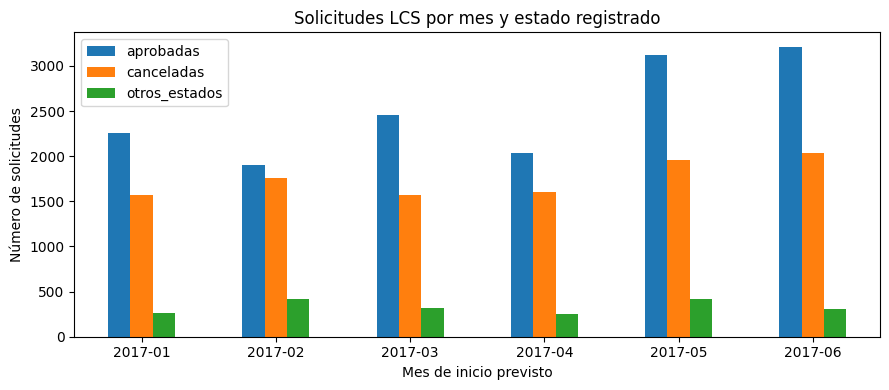

In [24]:
fig, ax = plt.subplots(figsize=(9, 4))

por_mes[['aprobadas', 'canceladas', 'otros_estados']].plot(
    kind='bar', ax=ax
)

ax.set(
    title='Solicitudes LCS por mes y estado registrado',
    xlabel='Mes de inicio previsto',
    ylabel='Número de solicitudes'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretación de resultados.** De las 27,448 solicitudes LCS analizadas, 14,980 (54.6 %) figuran como aprobadas, 10,491 (38.2 %) como canceladas y 1,977 (7.2 %) presentan otros estados administrativos. Estos estados corresponden a los registrados en la base histórica y no permiten determinar qué cierres se ejecutaron efectivamente.

El número de solicitudes aumenta notablemente en mayo y junio, cuando se registran alrededor de 5,500 solicitudes mensuales, frente a aproximadamente 4,100 durante enero-abril. Este incremento no implica necesariamente una mayor cantidad de cierres ejecutados. Más adelante se analiza si también se observa en los corredores seleccionados para el proyecto.

### 5.2. Anticipación administrativa y actualización de registros

La anticipación se define como `Start Date - Request Date`: mide cuánto antes del inicio previsto se creó administrativamente la solicitud. No equivale a una fecha de difusión pública ni demuestra que toda la información contenida en la exportación estuviera disponible en ese instante. Una anticipación negativa indica que la fecha de solicitud registrada es posterior al comienzo previsto.

Se examina también `Last Update` para identificar registros cuya versión final pudo incorporar modificaciones posteriores al inicio programado.

In [13]:
sol['anticipacion_dias']=(sol['Start Date_dt']-sol['Request Date_dt']).dt.total_seconds()/86400
renglones=[
    ('Solicitudes',f'{len(sol):,}'),
    ('Anticipación mediana (días)',f'{sol["anticipacion_dias"].median():.2f}'),
    ('Solicitudes ≥24 h antes',f'{int(sol["anticipacion_dias"].ge(1).sum()):,}'),
    ('Porcentaje ≥24 h antes',f'{sol["anticipacion_dias"].ge(1).mean()*100:.2f}%'),
    ('Solicitudes posteriores al inicio',f'{int(sol["anticipacion_dias"].lt(0).sum()):,}'),
    ('Actualizaciones posteriores al inicio',f'{int((sol["Last Update_dt"]>sol["Start Date_dt"]).sum()):,}')
]
display(pd.DataFrame(renglones,columns=['Indicador','Valor']))

print('Solicitudes con Request Date posterior al inicio programado:',int(sol['anticipacion_dias'].lt(0).sum()))


,Indicador,Valor
0,Solicitudes,"27,448"
1,Anticipación mediana (días),7.54
2,Solicitudes ≥24 h antes,"25,896"
3,Porcentaje ≥24 h antes,94.35%
4,Solicitudes posteriores al inicio,495
5,Actualizaciones posteriores al inicio,"14,123"


Solicitudes con Request Date posterior al inicio programado: 495


**Interpretación de resultados.** Durante enero-junio de 2017, las solicitudes LCS se registraron con una anticipación mediana de **7.54 días** respecto al inicio programado. De las 27,448 solicitudes analizadas, **25,896 (94.35 %)** tienen una fecha de solicitud al menos 24 horas anterior al inicio previsto, mientras que **495** se registraron después de esa fecha. Además, **14,123 (51.5 %)** presentan una última actualización posterior al inicio programado.

Estos resultados muestran que la mayoría de las solicitudes se genera con anticipación. Sin embargo, la base histórica no permite conocer qué información contenían originalmente ni cómo cambió con las actualizaciones. Por tanto, no es posible asegurar que todos los datos disponibles en la exportación pudieran haberse utilizado para realizar pronósticos antes de las intervenciones.

### 5.3. Duración programada, tipo de trabajo y carriles

Esta sección analiza las solicitudes LCS correspondientes a **enero-mayo de 2017**, dejando junio para un análisis separado. Se examinan la duración programada de las intervenciones, los tipos de trabajo y el número de carriles declarados.

La duración programada se calcula como la diferencia entre las fechas y horas previstas de finalización (`End Date`) e inicio (`Start Date`). Los registros con duraciones nulas o negativas se excluyen del cálculo de exposición temporal. Además, un valor de cero en `Closure Lanes` no implica necesariamente que la solicitud sea incorrecta o que no se haya realizado alguna intervención.

Las duraciones analizadas corresponden a los horarios programados y no necesariamente al tiempo durante el cual permanecieron cerrados los carriles.

,Control,Solicitudes
0,Solicitudes de enero–mayo,21895
1,End Date ausente,0
2,Duración programada ≤ 0 horas,47
3,Duración programada > 24 horas,205
4,Duración programada > 72 horas,123
5,Duración programada > 7 días,79


,Horas
count,21848.000000
mean,17.260299
std,219.623834
min,0.233333
50%,7.000000
90%,10.966667
95%,12.966667
99%,23.984333
max,13607.966667


Tipos de trabajo más frecuentes, enero–mayo:


,Solicitudes,Porcentaje
Trabajo,,
Roadside,3895,17.8
Traffic Guidance,3477,15.9
Pavement,2566,11.7
Construction,2259,10.3
Barrier,2003,9.1
Other,1990,9.1
Bridge,1612,7.4
Electrical,1561,7.1
Miscellaneous,956,4.4


Carriles declarados cerrados, enero–mayo:


,Solicitudes,Porcentaje
Carriles,,
0,1338,6.1
1,13766,62.9
2,5738,26.2
3,905,4.1
4,108,0.5
5,28,0.1
6,8,0.0
7,3,0.0
9,1,0.0


Fracción de carriles declarados cerrados (cuando 0 ≤ cerrados ≤ totales):
Registros válidos: 21895 / 21895


,Fracción
count,21895.000000
mean,0.609553
std,0.319690
min,0.000000
50%,0.500000
90%,1.000000
95%,1.000000
max,1.000000


Inicios previstos nocturnos (20:00-05:59): 13,493 de 21,895 (61.6 %)


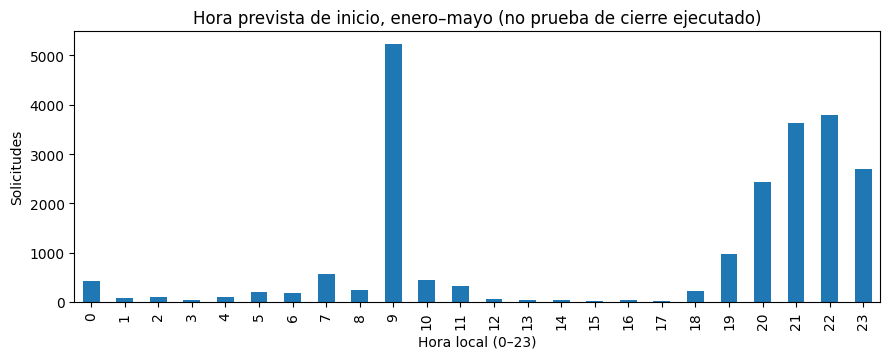

In [14]:
desarrollo=sol.loc[sol['Start Date_dt']<pd.Timestamp('2017-06-01')].copy()
calidad=pd.DataFrame([
    ['Solicitudes de enero–mayo',len(desarrollo)],
    ['End Date ausente',int(desarrollo['End Date_dt'].isna().sum())],
    ['Duración programada ≤ 0 horas',int(desarrollo['duracion_programada_h'].le(0).sum())],
    ['Duración programada > 24 horas',int(desarrollo['duracion_programada_h'].gt(24).sum())],
    ['Duración programada > 72 horas',int(desarrollo['duracion_programada_h'].gt(72).sum())],
    ['Duración programada > 7 días',int(desarrollo['duracion_programada_h'].gt(168).sum())],
],columns=['Control','Solicitudes'])
display(calidad)
positivas=desarrollo.loc[desarrollo.duracion_programada_h.gt(0),'duracion_programada_h']
display(positivas.describe(percentiles=[.5,.9,.95,.99]).rename('Horas').to_frame())
print('Tipos de trabajo más frecuentes, enero–mayo:')
tipos=desarrollo['Work Type'].fillna('No registrado').value_counts().rename_axis('Trabajo').to_frame('Solicitudes')
tipos['Porcentaje']=(100*tipos['Solicitudes']/len(desarrollo)).round(1)
display(tipos)
print('Carriles declarados cerrados, enero–mayo:')
carriles=desarrollo['Closure Lanes'].value_counts(dropna=False).sort_index().rename_axis('Carriles').to_frame('Solicitudes')
carriles['Porcentaje']=(100*carriles['Solicitudes']/len(desarrollo)).round(1)
display(carriles)
print('Fracción de carriles declarados cerrados (cuando 0 ≤ cerrados ≤ totales):')
num=pd.to_numeric(desarrollo['Closure Lanes'],errors='coerce')
den=pd.to_numeric(desarrollo['Total Lanes'],errors='coerce')
filt=num.ge(0)&den.gt(0)&num.le(den)
print('Registros válidos:',int(filt.sum()),'/',len(desarrollo))
if filt.any():
    display((num[filt]/den[filt]).describe(percentiles=[.5,.9,.95]).rename('Fracción').to_frame())

inicios_nocturnos=int(((desarrollo['Start Date_dt'].dt.hour >= 20) |
    (desarrollo['Start Date_dt'].dt.hour < 6)).sum())
print('Inicios previstos nocturnos (20:00-05:59):',
    f'{inicios_nocturnos:,}', 'de', f'{len(desarrollo):,}',
    f'({100*inicios_nocturnos/len(desarrollo):.1f} %)')

fig,ax=plt.subplots(figsize=(9,3.7))
desarrollo['Start Date_dt'].dt.hour.value_counts().reindex(range(24),fill_value=0).plot.bar(ax=ax)
ax.set(title='Hora prevista de inicio, enero–mayo (no prueba de cierre ejecutado)',
       xlabel='Hora local (0–23)',ylabel='Solicitudes')
plt.tight_layout();plt.show()


**Interpretación de horarios y duraciones.** Entre enero y mayo de 2017, **13,493 de las 21,895 solicitudes (61.6 %)** tienen un inicio programado entre las 20:00 y las 05:59. La **duración programada mediana es de 7 horas**. Estos resultados corresponden al conjunto de solicitudes LCS del periodo, no únicamente a las asociadas con la red del proyecto.

También se identifican **79 solicitudes con duraciones programadas superiores a siete días**, incluida una de aproximadamente 13,608 horas. Estos valores extremos requieren especial atención, pues no implican que los carriles permanecieran cerrados de manera continua durante esos periodos.

### 5.4. Vinculación con aristas del grafo

En esta sección se analiza cuántas solicitudes LCS pueden asociarse espacialmente con las **273 aristas de corredor** del proyecto, utilizando los criterios establecidos en la sección 3. Se distingue entre las asociaciones por superposición de tramos y las coincidencias puntuales.

También se calcula, para cada mes, el porcentaje de solicitudes asociadas con la red respecto al total de solicitudes con inicio programado durante ese mismo mes. Este indicador permite examinar cómo varía la correspondencia espacial a lo largo del periodo analizado.

In [15]:
asociadas=sol.loc[sol['DB ID'].isin(rel['DB ID'])].copy()
resumen_vinculo=[
    ('Solicitudes totales',f'{len(sol):,}'),
    ('Solicitudes asociadas (criterio inclusivo)',f'{len(asociadas):,}'),
    ('Solicitudes aprobadas asociadas (estado al exportar)',
     f'{int(asociadas.Status.eq("Approved").sum()):,}'),
    ('Pares solicitud–arista (inclusivos)',f'{len(rel):,}'),
    ('Aristas con alguna asociación inclusiva',f'{rel.edge_id.nunique():,} de {len(corr):,}'),
    ('Solicitudes con intersección positiva',
     f'{rel.loc[rel.pm_overlap_mi>0,"DB ID"].nunique():,}'),
    ('Solicitudes puntuales asociadas',
     f'{rel.loc[rel.tipo_espacial.isin(["punto_interior","punto_extremo"]),"DB ID"].nunique():,}'),
    ('Solicitudes puntuales aprobadas al exportar',
     f'{int(sol.loc[sol["DB ID"].isin(solo_punto),"Status"].eq("Approved").sum()):,}'),
    ('Mediana anticipación asociadas (días)',f'{asociadas.anticipacion_dias.median():.2f}')
]
display(pd.DataFrame(resumen_vinculo,columns=['Indicador','Valor']))
display(asociadas.groupby('mes').agg(solicitudes=('DB ID','count'),
                aprobadas_al_exportar=('Status',lambda s:s.eq('Approved').sum())).astype(int))

,Indicador,Valor
0,Solicitudes totales,"27,448"
1,Solicitudes asociadas (criterio inclusivo),"1,806"
2,Solicitudes aprobadas asociadas (estado al exp...,"1,134"
3,Pares solicitud–arista (inclusivos),"3,609"
4,Aristas con alguna asociación inclusiva,242 de 273
5,Solicitudes con intersección positiva,800
6,Solicitudes puntuales asociadas,"1,006"
7,Solicitudes puntuales aprobadas al exportar,602
8,Mediana anticipación asociadas (días),8.59


,solicitudes,aprobadas_al_exportar
mes,,
2017-01,338,175
2017-02,403,193
2017-03,353,232
2017-04,286,219
2017-05,296,217
2017-06,130,98


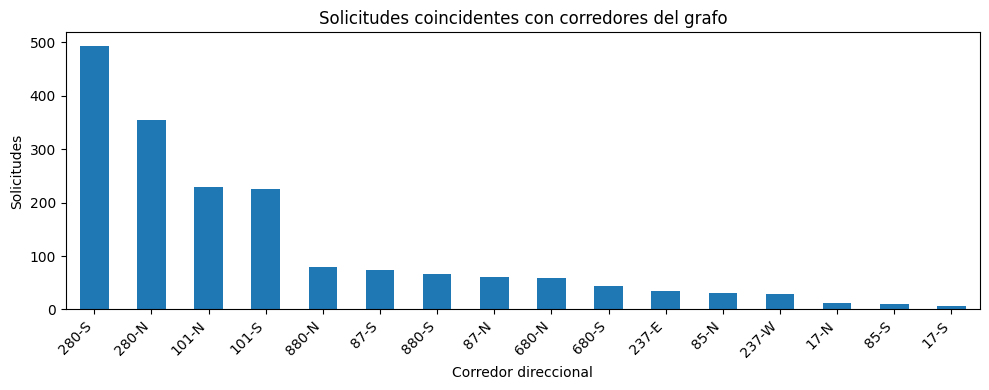

In [16]:
fig, ax=plt.subplots(figsize=(10,4))
orden=asociadas['road_dir'].value_counts()
orden.plot(kind='bar',ax=ax)
ax.set(title='Solicitudes coincidentes con corredores del grafo',ylabel='Solicitudes',xlabel='Corredor direccional')
plt.xticks(rotation=45,ha='right');plt.tight_layout();plt.show()

In [17]:
resumen_mensual=por_mes[['solicitudes']].join(
    asociadas.groupby('mes')['DB ID'].size().rename('asociadas')).fillna(0)
resumen_mensual['asociadas']=resumen_mensual['asociadas'].astype(int)
resumen_mensual['vinculacion_pct']=100*resumen_mensual['asociadas']/resumen_mensual['solicitudes']
display(resumen_mensual.style.format({'vinculacion_pct':'{:.2f}%'}))


,solicitudes,asociadas,vinculacion_pct
mes,,,
2017-01,4095,338,8.25%
2017-02,4078,403,9.88%
2017-03,4334,353,8.14%
2017-04,3890,286,7.35%
2017-05,5498,296,5.38%
2017-06,5553,130,2.34%


**Interpretación de resultados.** La proporción de solicitudes LCS asociadas con la red del proyecto alcanza su máximo en febrero (9.88 %) y disminuye progresivamente hasta junio (2.34 %). Esta reducción contrasta con el aumento del número total de solicitudes durante mayo y junio.

Los resultados muestran que la evolución general de las solicitudes del Distrito 4 no necesariamente refleja la actividad en los corredores seleccionados. Sin embargo, las asociaciones espaciales identificadas no permiten determinar cuántos cierres se ejecutaron efectivamente.

Junio se incluye únicamente con fines descriptivos, ya que sus datos fueron utilizados previamente en el Avance 4.

### 5.4.1. Exportación de solicitudes asociadas con la red

Se genera un archivo con una fila por cada asociación entre una solicitud LCS y una arista del grafo. Se incluyen la clasificación espacial, el tipo de instalación vial, las características de la intervención y las fechas relevantes. Cada solicitud se identifica mediante `event_key`, un identificador derivado de `DB ID` que facilita su seguimiento. Se excluyen nombres, teléfonos y notas de texto libre.

El archivo contiene información histórica que pudo haber sido modificada después de las fechas programadas para las intervenciones. Por ello, **no puede utilizarse directamente para evaluar modelos de predicción anticipada**. Para ese propósito sería necesario conocer qué información estaba efectivamente disponible al momento de realizar cada pronóstico.

In [18]:
# Tabla depurada de asociaciones por instalación, geometría y tiempos.
# NO usar campos retrospectivos directamente como predictores históricos.
CAMPOS_EVENTO=['DB ID','road_dir','Facility','Type','Work Type','Status',
  'Start Date_dt','End Date_dt','Request Date_dt','Last Update_dt',
  'Status 1022','Status 1022 Date_dt','Status 1097','Status 1097 Date_dt',
  'Status 1098','Status 1098 Date_dt','Closure Lanes','Total Lanes',
  'cancelacion_campo','inicio_reportado','fin_reportado',
  'intervalo_operativo_valido','solicitud_antes_inicio_24h']

tabla_eventos=(rel.merge(sol[CAMPOS_EVENTO],on='DB ID',how='left',validate='many_to_one')
  .merge(sol_sp[['DB ID','sol_inf','sol_sup']],on='DB ID',validate='many_to_one'))
tabla_eventos['event_key']='LCS-D04-2017-'+tabla_eventos['DB ID'].astype(str)
tabla_eventos['ambito_instalacion']=np.select([
  tabla_eventos['Facility'].eq('Freeway'),
  tabla_eventos['Facility'].isin(['On Ramp','Off Ramp']),
  tabla_eventos['Facility'].eq('Connector')],
  ['calzada_principal','rampa','conector'],default='otra_instalacion')
tabla_eventos['solicitud_puntual']=tabla_eventos['tipo_espacial'].isin(
    ['punto_interior','punto_extremo'])
tabla_eventos['tiempo_planteado_horas']=(
    tabla_eventos['End Date_dt']-tabla_eventos['Start Date_dt']).dt.total_seconds()/3600

EXPORTAR={
'event_key':'event_key','edge_id':'edge_id','road_dir':'road_dir',
'Facility':'facility','Type':'closure_type','Work Type':'work_type',
'ambito_instalacion':'ambito_instalacion',
'tipo_espacial':'geometry_type',
'pm_overlap_mi':'spatial_overlap_miles',
'sol_inf':'start_abs_pm','sol_sup':'end_abs_pm',
'Start Date_dt':'planned_start','End Date_dt':'planned_end',
'Request Date_dt':'administrative_request_time',
'Closure Lanes':'declared_closed_lanes','Total Lanes':'declared_total_lanes',
'solicitud_antes_inicio_24h':'request_24h_before_planned',
'Status':'final_status_at_export',
'cancelacion_campo':'field_cancellation_flag',
'Status 1022 Date_dt':'field_cancellation_time',
'inicio_reportado':'operational_start_reported',
'fin_reportado':'operational_end_reported',
'intervalo_operativo_valido':'valid_operational_interval',
'Status 1097 Date_dt':'operational_start_time',
'Status 1098 Date_dt':'operational_end_time',
'Last Update_dt':'last_administrative_update'}
tabla_export=tabla_eventos[list(EXPORTAR)].rename(columns=EXPORTAR)
assert len(tabla_export)==len(rel)
assert not tabla_export.duplicated(['event_key','edge_id']).any()
assert tabla_export['event_key'].nunique()==rel['DB ID'].nunique()
assert tabla_export['facility'].notna().all()
assert not {'DB ID','Submitter','Remarks','Inspector/Supervisor'}.intersection(tabla_export.columns)
ruta_eventos=SALIDA/'eventos_lcs_por_arista_d04_2017_retro.csv'
tabla_export.to_csv(ruta_eventos,index=False)
print('Tabla reutilizable (RETROSPECTIVA, no predictor listo):',ruta_eventos.name)
print('Filas:',len(tabla_export),'| eventos:',tabla_export.event_key.nunique(),
      '| aristas:',tabla_export.edge_id.nunique())
display(tabla_export['ambito_instalacion'].value_counts().rename_axis(
    'Ambito de instalación').to_frame('Asociaciones'))


Tabla reutilizable (RETROSPECTIVA, no predictor listo): eventos_lcs_por_arista_d04_2017_retro.csv
Filas: 3609 | eventos: 1806 | aristas: 242


,Asociaciones
Ambito de instalación,
calzada_principal,2292
rampa,802
otra_instalacion,488
conector,27


### 5.5. Presencia temporal programada

Para medir la presencia temporal de las solicitudes LCS en la red, se construye una secuencia de instantes separados por **cinco minutos** para cada una de las 273 aristas de corredor. Se identifica cuándo cada instante coincide con el horario programado de al menos una solicitud asociada espacialmente con la arista. Si varias solicitudes coinciden, el instante se cuenta una sola vez.

El indicador expresa el **porcentaje de pares arista–instante con presencia programada** respecto al total de pares posibles durante el periodo analizado. No depende de la disponibilidad de mediciones de velocidad ni representa directamente episodios de congestión.

El análisis principal considera las solicitudes clasificadas como `Freeway` que figuran como aprobadas (`Approved`) en la base histórica, incluyendo tanto asociaciones de tramo como puntuales. Para evaluar la sensibilidad de los resultados, se realizan las siguientes comparaciones:

| Comparación | Propósito |
|---|---|
| `Freeway`, aprobadas | Indicador principal para la calzada de autopista. |
| Todas las instalaciones, aprobadas | Evaluar la influencia de incluir rampas y otras instalaciones. |
| Solo rampas, aprobadas | Identificar la presencia programada en accesos y salidas. |
| `Freeway`, sin marca `10-22` | Examinar el efecto de excluir solicitudes con cancelación operativa reportada. |
| Intervalos `10-97`/`10-98` completos | Comparar con los periodos de operación reportados. |

También se examina la influencia de las asociaciones puntuales y de tramo sobre los resultados.

**Los indicadores describen horarios programados o reportados, no cierres efectivamente comprobados.** Asimismo, el estado de aprobación corresponde a la base histórica y no necesariamente al estado conocido antes de cada intervención.

El análisis principal comprende **enero-mayo de 2017**; junio se utiliza únicamente con fines descriptivos. Los horarios se interpretan en tiempo local y será necesario considerar los cambios de horario de verano antes de relacionarlos con las mediciones de velocidad.

In [19]:
# Prepara eventos con tiempos programados; conserva los estados ÚNICAMENTE para
# estratificación descriptiva ex post (no para características de predicción).
evt=rel.merge(sol[['DB ID','Start Date_dt','End Date_dt','Status','Facility','Type',
  'Status 1022','cancelacion_campo','inicio_reportado','fin_reportado',
  'intervalo_operativo_valido','Status 1097 Date_dt','Status 1098 Date_dt','Closure Lanes']],on='DB ID',
              how='left',validate='many_to_one')
evt=evt.loc[evt['Start Date_dt'].notna() & evt['End Date_dt'].notna()
            & evt['End Date_dt'].gt(evt['Start Date_dt'])].copy()
evt['dur_h']=(evt['End Date_dt']-evt['Start Date_dt']).dt.total_seconds()/3600

MALLA_INICIO=pd.Timestamp('2017-01-01 00:00:00')
MALLA_FIN=pd.Timestamp('2017-07-01 00:00:00')
INST = pd.date_range(MALLA_INICIO,MALLA_FIN,freq='5min',inclusive='left')
N_ARISTAS=len(corr)
IDS_ARISTAS=pd.Index(corr['edge_id'].astype(str))
assert IDS_ARISTAS.is_unique
assert len(INST)==181*24*12, 'Revisar definición de calendario de 5 minutos'
print('Malla:',len(INST),'instantes ×',N_ARISTAS,'aristas =',len(INST)*N_ARISTAS,
      'pares arista–instante posibles')

def ocupar_grilla(eventos):
    """Máscara booleana arista × instante, unión de ventanas [inicio, fin)."""
    cambios=np.zeros((N_ARISTAS,len(INST)+1),dtype=np.int32)
    if eventos.empty:
        return np.zeros((N_ARISTAS,len(INST)),dtype=bool)
    ev=eventos.loc[eventos['Start Date_dt'].lt(MALLA_FIN)
                   & eventos['End Date_dt'].gt(MALLA_INICIO)].copy()
    if ev.empty:
        return np.zeros((N_ARISTAS,len(INST)),dtype=bool)
    filas=IDS_ARISTAS.get_indexer(ev['edge_id'].astype(str))
    if (filas<0).any():
        raise ValueError('Aristas no localizadas en el grafo')
    # Primer instante de la grilla >= inicio, primer instante >= fin.
    # searchsorted(..., side='left') aplica convención [inicio, fin).
    i0=INST.searchsorted(ev['Start Date_dt'].to_numpy(),side='left')
    i1=INST.searchsorted(ev['End Date_dt'].to_numpy(),side='left')
    i0=np.clip(i0,0,len(INST)).astype(np.int64)
    i1=np.clip(i1,0,len(INST)).astype(np.int64)
    valid=i1>i0
    np.add.at(cambios,(filas[valid],i0[valid]),1)
    np.add.at(cambios,(filas[valid],i1[valid]),-1)
    return np.cumsum(cambios[:,:-1],axis=1)>0

# Validación unitaria de límites y doble conteo con una función independiente.
def comprobar_intervalos():
    global INST, IDS_ARISTAS, N_ARISTAS
    grilla_real,ids_reales,n_reales=INST,IDS_ARISTAS,N_ARISTAS
    try:
        INST=pd.date_range('2017-01-01 00:00','2017-01-01 00:20',freq='5min',inclusive='left')
        IDS_ARISTAS=pd.Index(['PRUEBA']);N_ARISTAS=1
        test=pd.DataFrame([
            {'edge_id':'PRUEBA','Start Date_dt':pd.Timestamp('2017-01-01 00:01'),
             'End Date_dt':pd.Timestamp('2017-01-01 00:11')},
            {'edge_id':'PRUEBA','Start Date_dt':pd.Timestamp('2017-01-01 00:06'),
             'End Date_dt':pd.Timestamp('2017-01-01 00:11')},
        ])
        result=ocupar_grilla(test)[0].tolist()
        assert result==[False,True,True,False],f'Prueba límites/unión falló: {result}'
    finally:
        INST,IDS_ARISTAS,N_ARISTAS=grilla_real,ids_reales,n_reales
comprobar_intervalos()
print('Prueba temporal: [inicio, fin) y sin duplicar solicitudes coincidentes → OK')


Malla: 52128 instantes × 273 aristas = 14230944 pares arista–instante programables
Prueba temporal: [inicio, fin) y sin duplicar solicitudes coincidentes → OK


Tabla principal - enero a mayo de 2017:


,Definicion,Pares_expuestos,Exposicion_pct
0,"Freeway, programadas y aprobadas","102,748",0.865 %
1,"Todas las instalaciones, aprobadas","131,084",1.104 %
2,"Rampas, aprobadas","43,128",0.363 %
3,"Freeway, sin cancelación 10-22 reportada","90,391",0.761 %
8,Con 10-97 y 10-98 válidos (todas las instalaciones),"44,066",0.371 %


Diagnósticos por geometría y precisión de carriles:


,Definicion,Pares_expuestos,Exposicion_pct
4,"Freeway, carriles cerrados declarados > 0","98,285",0.828 %
5,"Tramos, todas las instalaciones","106,505",0.897 %
6,"Puntos interiores, todas las instalaciones","51,393",0.433 %
7,"Tramos y puntos interiores, todas las instalaciones","130,246",1.097 %


Junio: comparación descriptiva, no periodo de prueba inédita:


,Escenario,Pares_expuestos,Exposicion_pct
5,freeway_aprobadas,"11,645",0.494 %
11,todas_instalaciones_aprobadas,"21,201",0.899 %
35,tramos_aprobados,"16,565",0.702 %


Freeway: aristas con presencia programada enero-mayo: 227 / 273
Freeway: noche 20:00-06:00: 1.615 %
Freeway: día 06:00-20:00: 0.33 %


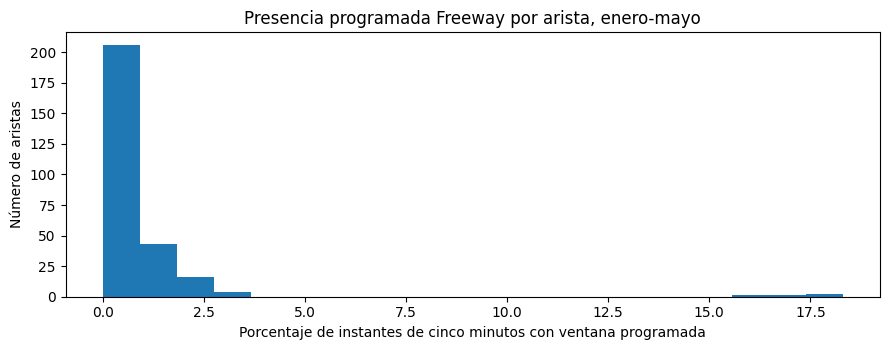

In [20]:
# Solo escenarios no redundantes. Conservan interpretación distinta.
ESCENARIOS={
    'freeway_aprobadas': (evt['Facility'].eq('Freeway') & evt['Status'].eq('Approved')),
    'todas_instalaciones_aprobadas': evt['Status'].eq('Approved'),
    'rampas_aprobadas': (evt['Facility'].isin(['On Ramp','Off Ramp']) & evt['Status'].eq('Approved')),
    'freeway_sin_1022': (evt['Facility'].eq('Freeway') & evt['Status'].eq('Approved') & ~evt['cancelacion_campo']),
    'freeway_carriles_positivos': (evt['Facility'].eq('Freeway') & evt['Status'].eq('Approved') & evt['Closure Lanes'].gt(0)),
    'tramos_aprobados': (evt['tipo_espacial'].eq('tramo_positivo') & evt['Status'].eq('Approved')),
    'puntos_interiores_aprobados': (evt['tipo_espacial'].eq('punto_interior') & evt['Status'].eq('Approved')),
    'tramos_y_puntos_interiores': (evt['tipo_espacial'].isin(['tramo_positivo','punto_interior']) & evt['Status'].eq('Approved')),
    'operativos_completos': None,
}
MASCARAS={}
for nombre, filtro in ESCENARIOS.items():
    if nombre=='operativos_completos':
        seleccion=evt.loc[evt['Status'].eq('Approved') & evt['intervalo_operativo_valido']].copy()
        seleccion['Start Date_dt']=seleccion['Status 1097 Date_dt']
        seleccion['End Date_dt']=seleccion['Status 1098 Date_dt']
    else:
        seleccion=evt.loc[filtro]
    MASCARAS[nombre]=ocupar_grilla(seleccion)

assert np.all(MASCARAS['freeway_sin_1022'] <= MASCARAS['freeway_aprobadas'])
assert np.all(MASCARAS['freeway_carriles_positivos'] <= MASCARAS['freeway_aprobadas'])
assert np.all(MASCARAS['freeway_aprobadas'] <= MASCARAS['todas_instalaciones_aprobadas'])
assert np.all(MASCARAS['rampas_aprobadas'] <= MASCARAS['todas_instalaciones_aprobadas'])
assert np.all(MASCARAS['tramos_aprobados'] <= MASCARAS['tramos_y_puntos_interiores'])
assert np.all(MASCARAS['puntos_interiores_aprobados'] <= MASCARAS['tramos_y_puntos_interiores'])
assert np.all(MASCARAS['tramos_y_puntos_interiores'] <= MASCARAS['todas_instalaciones_aprobadas'])
# Identidades: las rampas deben ser puntuales en este conjunto y no hay contactos
# entre dos intervalos extensos. Mantener pruebas para evitar interpretaciones erróneas.
assert not sub_aprob.loc[sub_aprob['Facility'].isin(['On Ramp','Off Ramp']) & sub_aprob['geometria'].eq('tramo')].shape[0]

MESES=pd.period_range('2017-01','2017-06',freq='M')
rows=[]
for nombre, mascara in MASCARAS.items():
    for mes in MESES:
        sel=np.asarray(INST.to_period('M')==mes)
        m=mascara[:,sel]
        rows.append({'Escenario':nombre,'Mes':str(mes),
            'Periodo':'enero_mayo' if str(mes)<='2017-05' else 'junio_diagnostico',
            'Aristas':N_ARISTAS,'Instantes_5min':int(sel.sum()),
            'Pares_arista_instante':int(m.size),
            'Pares_expuestos':int(m.sum()),
            'Exposicion_pct':100*m.mean(),
            'Aristas_con_exposicion':int(m.any(axis=1).sum())})
exposicion_mensual=pd.DataFrame(rows)
comparacion=(exposicion_mensual.loc[exposicion_mensual.Periodo.eq('enero_mayo')]
             .groupby('Escenario',sort=False)[['Pares_arista_instante','Pares_expuestos']]
             .sum().reset_index())
comparacion['Exposicion_pct']=100*comparacion['Pares_expuestos']/comparacion['Pares_arista_instante']

# Tabla principal: los nombres describen el universo de cada cifra.
claves_principales=['freeway_aprobadas','todas_instalaciones_aprobadas',
 'rampas_aprobadas','freeway_sin_1022','operativos_completos']
labels={
 'freeway_aprobadas':'Freeway, programadas y aprobadas',
 'todas_instalaciones_aprobadas':'Todas las instalaciones, aprobadas',
 'rampas_aprobadas':'Rampas, aprobadas',
 'freeway_sin_1022':'Freeway, sin cancelación 10-22 reportada',
 'operativos_completos':'Con 10-97 y 10-98 válidos (todas las instalaciones)',
 'freeway_carriles_positivos':'Freeway, carriles cerrados declarados > 0',
 'tramos_aprobados':'Tramos, todas las instalaciones',
 'puntos_interiores_aprobados':'Puntos interiores, todas las instalaciones',
 'tramos_y_puntos_interiores':'Tramos y puntos interiores, todas las instalaciones'
}
comparacion['Definicion']=comparacion.Escenario.map(labels)
print('Tabla principal - enero a mayo de 2017:')
display(comparacion.loc[comparacion.Escenario.isin(claves_principales),
  ['Definicion','Pares_expuestos','Exposicion_pct']]
  .style.format({'Exposicion_pct':'{:.3f} %','Pares_expuestos':'{:,.0f}'}))

print('Diagnósticos por geometría y precisión de carriles:')
display(comparacion.loc[~comparacion.Escenario.isin(claves_principales),
  ['Definicion','Pares_expuestos','Exposicion_pct']]
  .style.format({'Exposicion_pct':'{:.3f} %','Pares_expuestos':'{:,.0f}'}))
print('Junio: comparación descriptiva, no periodo de prueba inédita:')
display(exposicion_mensual.loc[exposicion_mensual.Periodo.eq('junio_diagnostico') &
  exposicion_mensual.Escenario.isin(['freeway_aprobadas','tramos_aprobados','todas_instalaciones_aprobadas']),
  ['Escenario','Pares_expuestos','Exposicion_pct']]
  .style.format({'Exposicion_pct':'{:.3f} %','Pares_expuestos':'{:,.0f}'}))

# Tablas completas en CSV; presentación breve en notebook.
resultado=[]
for escenario,mascara in MASCARAS.items():
    for etiqueta,selector in [('enero_mayo',np.asarray(INST<pd.Timestamp('2017-06-01'))),
                              ('junio_diagnostico',np.asarray(INST>=pd.Timestamp('2017-06-01')) )]:
        md=mascara[:,selector]
        for arista,n_exp in zip(IDS_ARISTAS,md.sum(axis=1).astype(int)):
            resultado.append({'Escenario':escenario,'Periodo':etiqueta,'edge_id':arista,
                'Instantes_5min':md.shape[1],'Instantes_expuestos':int(n_exp),
                'Exposicion_pct':100*int(n_exp)/md.shape[1]})
exposicion_aristas=pd.DataFrame(resultado)

mask_dev=np.asarray(INST<pd.Timestamp('2017-06-01'))
m_freeway=MASCARAS['freeway_aprobadas'][:,mask_dev]
m_tramos=MASCARAS['tramos_aprobados'][:,mask_dev]
horas_dev=INST[mask_dev].hour
es_noche=np.asarray((horas_dev>=20)|(horas_dev<6))
print('Freeway: aristas con presencia programada enero-mayo:',int(m_freeway.any(axis=1).sum()),'/',N_ARISTAS)
print('Freeway: noche 20:00-06:00:',round(100*m_freeway[:,es_noche].mean(),3),'%')
print('Freeway: día 06:00-20:00:',round(100*m_freeway[:,~es_noche].mean(),3),'%')

fig,ax=plt.subplots(figsize=(9.0,3.6))
ax.hist(100*m_freeway.mean(axis=1),bins=20)
ax.set(title='Presencia programada Freeway por arista, enero-mayo',
       xlabel='Porcentaje de instantes de cinco minutos con ventana programada',ylabel='Número de aristas')
plt.tight_layout();plt.show()

# Indicadores para la trazabilidad, sin generar interpretación narrativa.
pct=lambda clave:float(comparacion.set_index('Escenario').at[clave,'Exposicion_pct'])
porc_freeway=pct('freeway_aprobadas')
porc_union_total=pct('todas_instalaciones_aprobadas')
porc_freeway_sin1022=pct('freeway_sin_1022')
porc_rampas=pct('rampas_aprobadas')
porc_operativo=pct('operativos_completos')
porc_principal=pct('tramos_aprobados')
porc_union_interior=pct('tramos_y_puntos_interiores')


**Interpretación de resultados.** Entre enero y mayo de 2017, las solicitudes aprobadas clasificadas como `Freeway` presentan una **presencia programada del 0.865 %** de los pares arista–instante de la red. Al incluir solicitudes correspondientes a rampas y otras instalaciones, el porcentaje aumenta a **1.104 %**, mientras que al excluir las solicitudes `Freeway` con cancelación operativa reportada (`10-22`) disminuye a **0.761 %**. Por su parte, los intervalos operativos reportados mediante las marcas `10-97` y `10-98` representan el **0.371 %**, considerando todas las instalaciones.

**Distribución espacial y temporal.** Se identifica presencia programada en **227 de las 273 aristas** del grafo (83.2 %), aunque su distribución es muy desigual. La mayoría presenta porcentajes bajos, mientras que unas pocas alcanzan valores considerablemente mayores. Asimismo, la presencia programada es más elevada durante la noche (1.615 %) que durante el día (0.330 %).

Estos resultados describen la distribución espacial y temporal de las solicitudes LCS, pero no permiten establecer que las intervenciones se hayan ejecutado ni que hayan provocado alteraciones en las velocidades de circulación.

### 5.5.1. Influencia de las solicitudes asociadas con múltiples aristas

Para evaluar si unas pocas solicitudes tienen una influencia desproporcionada en la exposición programada, se identifican aquellas clasificadas como `Freeway`, aprobadas y asociadas con **diez o más aristas**. Se calcula su contribución al indicador general, evitando contar dos veces las coincidencias entre solicitudes sobre una misma arista e instante.


In [21]:
# Diagnóstico de solicitudes Freeway asociadas con 10 o más aristas.
# Separar presencia bruta del subconjunto de su contribución marginal exclusiva.
base_freeway=evt.loc[
    evt['Facility'].eq('Freeway') & evt['Status'].eq('Approved') &
    evt['Start Date_dt'].ge(pd.Timestamp('2017-01-01')) &
    evt['Start Date_dt'].lt(pd.Timestamp('2017-06-01'))
].copy()
aristas_solicitud=base_freeway.groupby('DB ID')['edge_id'].nunique()
ids_extensas=aristas_solicitud.index[aristas_solicitud.ge(10)]
eventos_extensos=base_freeway.loc[base_freeway['DB ID'].isin(ids_extensas)]
eventos_resto=base_freeway.loc[~base_freeway['DB ID'].isin(ids_extensas)]
selector_enero_mayo=np.asarray(INST<pd.Timestamp('2017-06-01'))
mask_extensas=ocupar_grilla(eventos_extensos)[:,selector_enero_mayo]
mask_resto=ocupar_grilla(eventos_resto)[:,selector_enero_mayo]
mask_total=MASCARAS['freeway_aprobadas'][:,selector_enero_mayo]
assert np.array_equal(mask_total,mask_extensas | mask_resto), 'Revisar ventanas que cruzan periodos'
n_expuestos_freeway=int(mask_total.sum())
n_subconjunto=int(mask_extensas.sum())
n_exclusivos=int((mask_extensas & ~mask_resto).sum())
n_compartidos=int((mask_extensas & mask_resto).sum())
assert n_subconjunto == n_exclusivos+n_compartidos
concentracion=pd.DataFrame({
    'Indicador':[
        'Solicitudes Freeway aprobadas con inicio enero-mayo',
        'Solicitudes asociadas con 10 o más aristas',
        'Participación de solicitudes extensas',
        'Pares expuestos por el subconjunto extenso (unión)',
        'Participación bruta respecto al total expuesto Freeway',
        'Pares atribuibles exclusivamente al subconjunto extenso',
        'Participación marginal exclusiva respecto al total Freeway',
        'Pares compartidos entre extensas y otras solicitudes',
    ],
    'Valor':[
        str(len(aristas_solicitud)),
        str(len(ids_extensas)),
        f'{100*len(ids_extensas)/len(aristas_solicitud):.1f} %',
        f'{n_subconjunto:,}',
        f'{100*n_subconjunto/n_expuestos_freeway:.1f} %',
        f'{n_exclusivos:,}',
        f'{100*n_exclusivos/n_expuestos_freeway:.1f} %',
        f'{n_compartidos:,}',
    ]
})
display(concentracion)


,Indicador,Valor
0,Solicitudes Freeway aprobadas con inicio enero...,503
1,Solicitudes asociadas con 10 o más aristas,11
2,Participación de solicitudes extensas,2.2 %
3,Pares expuestos por el subconjunto extenso (un...,"8,327"
4,Participación bruta respecto al total expuesto...,8.1 %
5,Pares atribuibles exclusivamente al subconjunt...,"8,327"
6,Participación marginal exclusiva respecto al t...,8.1 %
7,Pares compartidos entre extensas y otras solic...,0


**Interpretación de resultados.** Entre enero y mayo de 2017, **11 de las 503 solicitudes analizadas (2.2 %)** están asociadas con diez o más aristas. Estas solicitudes representan **8,327 pares arista–instante, equivalentes al 8.1 %** de la exposición programada total. Ninguno de esos pares coincide con los correspondientes a las demás solicitudes.

Aunque este pequeño grupo aporta una proporción de exposición superior a su participación en el número de solicitudes, **el 91.9 % restante corresponde a solicitudes asociadas con menos de diez aristas**. Por tanto, el indicador general no está dominado por las solicitudes que abarcan más aristas.

### 5.5.2. Concentración espacial de solicitudes en junio

Para analizar la presencia programada durante junio, se examinan las solicitudes aprobadas clasificadas como `Conventional Hwy`. Se busca identificar si algunas solicitudes abarcan tramos extensos de carretera y, por tanto, se asocian con numerosas aristas del grafo.

**Interpretación de resultados.** Se identifican **10 solicitudes** correspondientes a la carretera 280, de las cuales nueve abarcan aproximadamente **11.25 millas** y se asocian con 18 aristas cada una. La solicitud restante corresponde a una ubicación puntual asociada con una arista. En conjunto, generan **163 asociaciones solicitud–arista**, aunque sus duraciones programadas son de solo 2 a 3 horas.

Estos resultados muestran que una cantidad reducida de solicitudes puede generar numerosas asociaciones espaciales, lo que contribuye a explicar la mayor presencia programada observada en junio al considerar todas las instalaciones. Sin embargo, esta correspondencia no implica que todas las aristas asociadas hayan experimentado cierres efectivos de carriles.

In [22]:
junio_conv=evt.loc[(evt['Status'].eq('Approved')) &
    (evt['Facility'].eq('Conventional Hwy')) &
    (evt['Start Date_dt'].ge(pd.Timestamp('2017-06-01'))) &
    (evt['Start Date_dt'].lt(pd.Timestamp('2017-07-01')))].copy()
junio_conv=junio_conv.merge(sol_sp[['DB ID','road_dir','sol_inf','sol_sup']],
    on='DB ID',how='left',validate='many_to_one')
res_junio=(junio_conv.groupby(['DB ID','road_dir'],as_index=False)
    .agg(aristas_asociadas=('edge_id','nunique'),
         postmilla_inicial=('sol_inf','first'),postmilla_final=('sol_sup','first'),
         inicio_programado=('Start Date_dt','first'),duracion_h=('dur_h','first'))
    .sort_values(['aristas_asociadas','inicio_programado'],ascending=[False,True]))
print('Solicitudes Conventional Hwy aprobadas en junio:',len(res_junio))
print('Pares solicitud-arista:',len(junio_conv))
display(res_junio.head(12))


Solicitudes Conventional Hwy aprobadas en junio: 10
Pares solicitud-arista: 163


,DB ID,road_dir,aristas_asociadas,postmilla_inicial,postmilla_final,inicio_programado,duracion_h
0,8879058,280-S,18,0.064,11.318,2017-06-05 09:30:00,2.0
5,8879100,280-N,18,0.064,11.318,2017-06-05 11:30:00,3.0
1,8879059,280-S,18,0.064,11.318,2017-06-06 09:30:00,2.0
6,8879102,280-N,18,0.064,11.318,2017-06-06 11:30:00,3.0
2,8879061,280-S,18,0.064,11.318,2017-06-07 09:30:00,2.0
7,8879103,280-N,18,0.064,11.318,2017-06-07 11:30:00,3.0
3,8879068,280-S,18,0.064,11.318,2017-06-08 09:30:00,2.0
8,8879104,280-N,18,0.064,11.318,2017-06-08 11:30:00,3.0
9,8879105,280-N,18,0.064,11.318,2017-06-09 11:30:00,3.0
4,8879092,280-S,1,11.318,11.318,2017-06-09 09:30:00,2.0


**Interpretación de resultados.** En junio de 2017 se identifican **10 solicitudes aprobadas** clasificadas como `Conventional Hwy` y asociadas con la carretera 280. Nueve de ellas abarcan el mismo intervalo de postmillas (0.064 a 11.318), equivalente a aproximadamente 11.25 millas, y se vinculan con 18 aristas cada una. Estas solicitudes se distribuyen entre el 5 y el 9 de junio, en ambos sentidos de circulación, con duraciones programadas de 2 a 3 horas. La solicitud restante corresponde a una ubicación puntual asociada con una arista.

En conjunto, las diez solicitudes generan **163 asociaciones solicitud-arista**. Esto muestra cómo un número reducido de solicitudes que abarcan tramos extensos puede producir numerosas asociaciones espaciales y contribuir a la presencia programada calculada para la red. Sin embargo, estas asociaciones no implican que todas las aristas involucradas hayan experimentado cierres efectivos de carriles.

In [23]:
# Exportar resúmenes compactos (no matriz binaria ni datos personales).
ruta_mensual=SALIDA/'exposicion_temporal_mensual.csv'
ruta_aristas=SALIDA/'exposicion_por_arista_y_periodo.csv'
exposicion_mensual.to_csv(ruta_mensual,index=False)
exposicion_aristas.to_csv(ruta_aristas,index=False)
manifiesto['statistics'].update({
    'db_id_duplicados':int(sol['DB ID'].duplicated().sum()),
    'freeway_solicitudes_enero_mayo':int(len(aristas_solicitud)),
    'freeway_solicitudes_10_aristas_o_mas':int(len(ids_extensas)),
    'freeway_pares_expuestos_solicitudes_extensas':int(n_subconjunto),
    'freeway_pares_expuestos_extensas_exclusivos':int(n_exclusivos),
    'exposicion_pct_enero_mayo_freeway_programado':float(porc_freeway),
    'exposicion_pct_enero_mayo_todas_instalaciones_programado':float(porc_union_total),
    'eventos_con_duracion_no_positiva':int(sol['duracion_programada_h'].le(0).sum()),
    'aprobadas_asociadas_cancelacion_1022':int(sub_aprob['cancelacion_campo'].sum()),
    'aprobadas_asociadas_intervalo_operativo_valido':int(sub_aprob['intervalo_operativo_valido'].sum()),
    'registros_espaciales_puntuales':int(rel.pm_overlap_mi.eq(0).sum()),
    'solicitudes_puntuales_asociadas':int(len(solo_punto)),
    'exposicion_pct_enero_mayo_tramos_y_puntos_interiores':float(porc_union_interior),
    'exposicion_pct_enero_mayo_tramos_y_puntos_todos':float(porc_union_total)
})
manifiesto['definicion_exposicion']={
    'malla':'5 minutos uniformes locales, inicio de intervalo, DST ignorado',
    'ventana':'[Start Date, End Date) PROGRAMADOS',
    'denominador':'todas las aristas de corredor × marcas de tiempo de la malla',
    'union':'solicitudes superpuestas se cuentan una vez por par arista-instante; puntos son senales de localizacion, no extension' ,
    'principal':'Facility Freeway y Status Approved en exporte; programación retrospectiva, no prueba de ejecución',
    'alternativas':['todas las instalaciones vs Freeway','rampas','filtrado 10-22','intervalos 10-97/10-98 completos','geometria por tramos y puntos','Freeway con carriles declarados positivos'],
    'not_predictor':'Status, marcas operativas, ventanas del exporte y Request Date no garantizan publicación histórica ni estabilidad as-of'
}
for etiqueta,path in {'solicitudes':ruta_sol,'correspondencias':ruta_rel,
                     'embudo':ruta_embudo,'exposicion_mensual':ruta_mensual,
                     'exposicion_por_arista':ruta_aristas,'eventos_depurados':ruta_eventos}.items():
    manifiesto['output_hashes_sha256'][etiqueta]=sha256(path)
with open(SALIDA/'trazabilidad.json','w',encoding='utf-8') as f:
    json.dump(manifiesto,f,ensure_ascii=False,indent=2)
print('Carpeta de resultados y manifiesto:', SALIDA.name)

Carpeta de resultados y manifiesto: lcs_d04_2017_exploracion


## 5.6. Limitaciones para el uso predictivo

El análisis permite identificar la ubicación aproximada y los horarios programados de las solicitudes LCS. Sin embargo, existen algunas limitaciones que deben considerarse antes de incorporar esta información a modelos de predicción de tiempos de recorrido:

- **Disponibilidad histórica de la información.** La base contiene registros que pudieron modificarse después de las fechas programadas para las intervenciones. Por tanto, no es posible establecer con certeza qué información estaba disponible antes de cada evento. Para desarrollar modelos de predicción anticipada sería necesario contar con registros históricos fechados que permitan reconstruir la información disponible en cada momento.

- **Precisión espacial.** La asociación mediante postmillas permite relacionar solicitudes con las aristas del grafo, pero no determina exactamente qué carriles resultaron afectados ni hasta dónde pudieron extenderse sus efectos sobre el tráfico. Además, la red analizada comprende únicamente los corredores seleccionados del condado 85.

- **Ejecución de las intervenciones.** Una solicitud aprobada no garantiza que el cierre se haya realizado. Aunque algunas solicitudes contienen marcas operativas, esta información es incompleta. Por ello, los indicadores calculados representan presencia programada o reportada, no afectaciones comprobadas en las velocidades de circulación.

- **Integración y evaluación predictiva.** Antes de relacionar las solicitudes con las mediciones de velocidad de PeMS, será necesario armonizar sus referencias temporales, incluyendo los cambios de horario de verano. Asimismo, dado que junio de 2017 ya fue utilizado en el Avance 4, no puede considerarse un periodo de evaluación predictiva independiente.

Estas limitaciones no impiden aprovechar la información LCS como una posible fuente de contexto para la predicción, pero hacen necesario comprobar su disponibilidad temporal y evaluar empíricamente su utilidad.

## 6. Conclusiones y siguiente experimento

**Correspondencia espacial.** De las **27,448 solicitudes LCS** analizadas para enero-junio de 2017, **1,806** se asociaron con al menos una de las 273 aristas de corredor del proyecto, generando **3,609 asociaciones solicitud-arista**. Se identificaron **1,006 solicitudes con asociaciones exclusivamente puntuales**, que permiten establecer una ubicación aproximada, pero no determinar la extensión de una posible intervención. La clasificación por tipo de instalación también permitió distinguir las solicitudes correspondientes a la calzada principal de aquellas relacionadas con rampas y otras instalaciones.

**Características temporales y disponibilidad de información.** Las solicitudes presentan una anticipación administrativa mediana de **7.54 días**, y el 94.35 % se registró al menos 24 horas antes del inicio programado. Sin embargo, muchas fueron actualizadas posteriormente, por lo que la base histórica no permite reconstruir con certeza qué información estaba disponible antes de cada intervención. Asimismo, una solicitud aprobada no constituye evidencia suficiente de que el cierre se haya ejecutado.

**Presencia temporal programada.** Durante enero-mayo, las solicitudes aprobadas clasificadas como `Freeway` coinciden con el **0.865 % de los pares arista-instante** de la red. Esta proporción es mayor durante la noche (1.615 %) que durante el día (0.330 %). Aunque se identifica presencia programada en **227 de las 273 aristas**, su distribución es desigual: la mayoría presenta porcentajes bajos, mientras que algunas concentran valores considerablemente mayores. Estos indicadores describen la programación administrativa de posibles intervenciones, no sus efectos observados sobre la circulación.

**Implicaciones para el proyecto.** Los resultados muestran que los registros LCS pueden proporcionar información contextual sobre la ubicación y programación de posibles interrupciones. Sin embargo, todavía no se ha determinado si esta información permite explicar o anticipar cambios en los tiempos de recorrido. Además, debido a la baja frecuencia de los periodos con presencia programada, una posible mejora predictiva concentrada en ellos podría pasar inadvertida en las métricas globales.

**Siguiente experimento.** Se propone relacionar las solicitudes LCS con las velocidades observadas en PeMS, examinando las aristas asociadas y sus vecinas, y controlando los patrones habituales de circulación. El análisis deberá distinguir el comportamiento dentro y fuera de las ventanas programadas, así como comprobar la sensibilidad de los resultados a las duraciones extremas. Para evaluar una mejora predictiva real, será necesario establecer qué información LCS estaba disponible antes de cada pronóstico y compararla con modelos que no incorporen estas variables. Si no es posible reconstruir dicha disponibilidad histórica, el experimento deberá limitarse inicialmente al análisis retrospectivo de asociaciones entre las solicitudes y las velocidades observadas.
